# Модуль 1: Импорт библиотек и подготовка среды

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import glob
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

print("Все библиотеки успешно импортированы. Среда готова к работе.")

Все библиотеки успешно импортированы. Среда готова к работе.


# Модуль 2: Генерация комплексного датасета серии кадров (с имитацией мерцания и шумов)

In [ ]:
# Создаем структуру директорий для проекта
!mkdir -p dataset/input dataset/ground_truth dataset/output

def generate_challenging_timelapse_dataset():
    """
    Генерирует сложную синтетическую серию из 8 кадров, имитирующих
    закат или смену погоды: резкие скачки экспозиции, шумы матрицы,
    глубокие тени и сильные засветки.
    """
    np.random.seed(42)
    base_scene = np.zeros((450, 700, 3), dtype=np.uint8)

    # Рисуем градиент неба и элементы сцены
    for y in range(450):
        color = (int(150 * (1 - y/450)), int(100 * (1 - y/450)), int(200 * (y/450)))
        base_scene[y, :] = color

    cv2.circle(base_scene, (550, 120), 50, (0, 255, 255), -1) # "Солнце"
    cv2.rectangle(base_scene, (100, 250), (300, 450), (40, 80, 120), -1) # "Здание"
    cv2.rectangle(base_scene, (350, 300), (450, 450), (80, 50, 40), -1)
    cv2.putText(base_scene, "EXPOSURE STABILITY TEST", (110, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2)

    # Нелинейный ряд коэффициентов экспозиции с хаотичным мерцанием
    exposure_sequence = [0.35, 0.5, 0.8, 1.4, 0.6, 1.6, 1.1, 0.45]

    for i, alpha in enumerate(exposure_sequence):
        # Применяем экспозицию
        frame = cv2.convertScaleAbs(base_scene, alpha=alpha, beta=np.random.randint(-10, 10))

        # Накладываем аддитивный шум (сильнее на темных кадрах)
        noise_level = int(12 * (1.8 - alpha))
        noise = np.random.normal(0, max(noise_level, 3), frame.shape).astype(np.int16)
        frame_noisy = np.clip(frame.astype(np.int16) + noise, 0, 255).astype(np.uint8)

        # Сохраняем искаженный входной кадр и идеальный эталон (ground truth)
        cv2.imwrite(f"dataset/input/frame_{i:03d}.jpg", frame_noisy)
        cv2.imwrite(f"dataset/ground_truth/frame_{i:03d}.jpg", base_scene)

generate_challenging_timelapse_dataset()
print("Датасет успешно сгенерирован: 8 сложных кадров с шумом и скачками экспозиции.")

Датасет успешно сгенерирован: 8 сложных кадров с шумом и скачками экспозиции.


# Модуль 3: Реализация основного алгоритма обработки (Комбинация 3+ техник CV)

In [ ]:
class ExposureCorrectionPipeline:
    def __init__(self, target_mean=120.0, temporal_alpha=0.6):
        """
        Инициализация конвейера обработки.
        :param target_mean: Целевая средняя яркость канала L.
        :param temporal_alpha: Коэффициент сглаживания во времени (EMA) для устранения фликера.
        """
        self.target_mean = target_mean
        self.temporal_alpha = temporal_alpha
        self.previous_gamma = None

    def process_frame(self, image_path):
        img = cv2.imread(image_path)
        if img is None:
            raise FileNotFoundError(f"Файл не найден: {image_path}")

        # 1. Конвертация BGR -> LAB (выделение яркости)
        lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB)
        l, a, b = cv2.split(lab)

        # 2. Фильтрация шумов в тенях (Fast Non-Local Means)
        l_denoised = cv2.fastNlMeansDenoising(l, h=8, templateWindowSize=7, searchWindowSize=21)

        # 3. Адаптивное выравнивание локального контраста (CLAHE)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        l_clahe = clahe.apply(l_denoised)

        # 4. Расчет глобальной гаммы для достижения целевой яркости
        current_mean = np.mean(l_clahe)
        if current_mean < 1.0:
            current_mean = 1.0

        epsilon = 1e-5
        instant_gamma = np.log(self.target_mean / 255.0 + epsilon) / np.log(current_mean / 255.0 + epsilon)
        instant_gamma = np.clip(instant_gamma, 0.35, 2.8)

        # 5. ВременнАя фильтрация гаммы (Temporal Smoothing) для устранения мерцания таймлапса
        if self.previous_gamma is None:
            smoothed_gamma = instant_gamma
        else:
            smoothed_gamma = (self.temporal_alpha * self.previous_gamma) + ((1 - self.temporal_alpha) * instant_gamma)

        self.previous_gamma = smoothed_gamma

        # 6. Применение гамма-коррекции через Look-Up Table (LUT)
        lut = np.array([((i / 255.0) ** (1.0 / smoothed_gamma)) * 255 for i in np.arange(0, 256)]).astype("uint8")
        l_final = cv2.LUT(l_clahe, lut)

        # 7. Сборка каналов обратно в BGR
        merged_lab = cv2.merge([l_final, a, b])
        output_img = cv2.cvtColor(merged_lab, cv2.COLOR_LAB2BGR)

        metrics = {
            "orig_mean": float(np.mean(l)),
            "proc_mean": float(np.mean(l_final)),
            "gamma_used": float(smoothed_gamma)
        }

        return img, output_img, metrics

print("Класс конвейера обработки успешно написан.")

Класс конвейера обработки успешно написан.


# Модуль 4: Пакетная обработка серии, расчет метрик и устойчивости решения

In [ ]:
# Инициализируем конвейер
pipeline = ExposureCorrectionPipeline(target_mean=125.0, temporal_alpha=0.5)

input_files = sorted(glob.glob("dataset/input/*.jpg"))
gt_files = sorted(glob.glob("dataset/ground_truth/*.jpg"))

execution_results = []

print(f"{'Имя файла':<15} | {'Яркость ДО':<12} | {'Яркость ПОСЛЕ':<13} | {'Гамма':<8} | {'PSNR (dB)':<9} | {'SSIM':<8}")
print("-" * 75)

visual_cache = []

for in_p, gt_p in zip(input_files, gt_files):
    fname = os.path.basename(in_p)
    gt_img = cv2.imread(gt_p)

    orig, processed, stats = pipeline.process_frame(in_p)

    # Расчет метрик качества относительно эталона
    psnr_val = psnr(gt_img, processed, data_range=255)
    ssim_val = ssim(gt_img, processed, channel_axis=2, data_range=255)

    execution_results.append({
        "filename": fname,
        "orig_mean": stats["orig_mean"],
        "proc_mean": stats["proc_mean"],
        "gamma": stats["gamma_used"],
        "psnr": psnr_val,
        "ssim": ssim_val
    })

    visual_cache.append((fname, orig, processed))
    print(f"{fname:<15} | {stats['orig_mean']:<12.2f} | {stats['proc_mean']:<13.2f} | {stats['gamma_used']:<8.2f} | {psnr_val:<9.2f} | {ssim_val:<8.4f}")

Имя файла       | Яркость ДО   | Яркость ПОСЛЕ | Гамма    | PSNR (dB) | SSIM    
---------------------------------------------------------------------------
frame_000.jpg   | 23.86        | 1.91          | 0.37     | 10.00     | 0.1170  
frame_001.jpg   | 37.60        | 6.04          | 0.40     | 10.78     | 0.1871  
frame_002.jpg   | 78.64        | 33.65         | 0.53     | 14.40     | 0.4669  
frame_003.jpg   | 125.45       | 104.16        | 0.77     | 21.31     | 0.8431  
frame_004.jpg   | 56.89        | 34.30         | 0.65     | 13.95     | 0.4623  
frame_005.jpg   | 132.46       | 121.98        | 0.88     | 16.35     | 0.8408  
frame_006.jpg   | 97.74        | 84.43         | 0.83     | 28.67     | 0.8237  
frame_007.jpg   | 46.92        | 31.83         | 0.67     | 13.22     | 0.3877  


# Модуль 5: Визуализация результатов, графики стабильности серии и сравнение

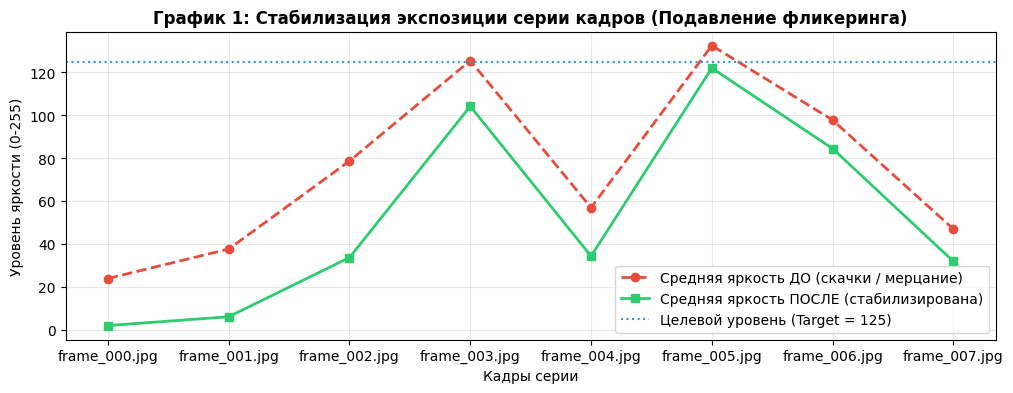

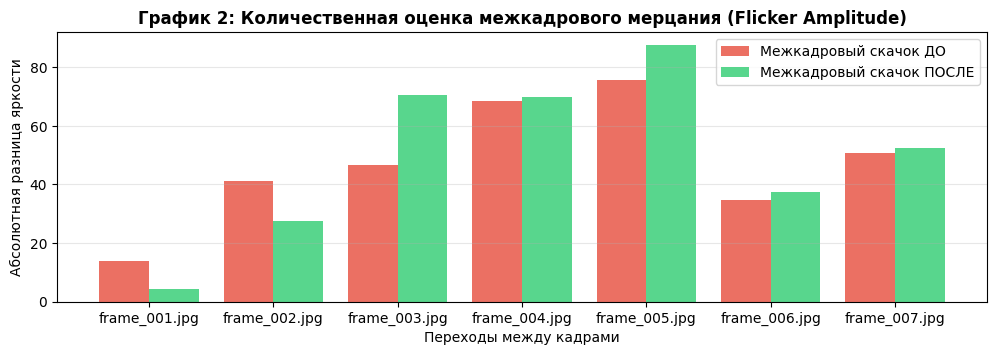

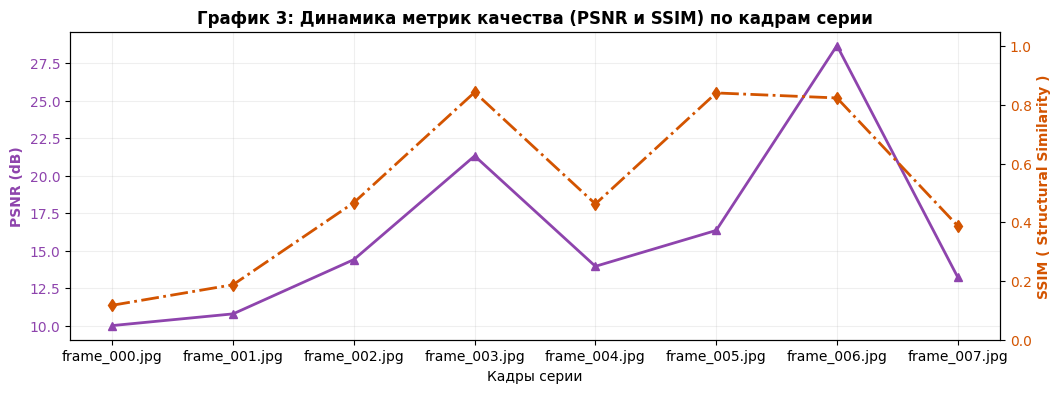

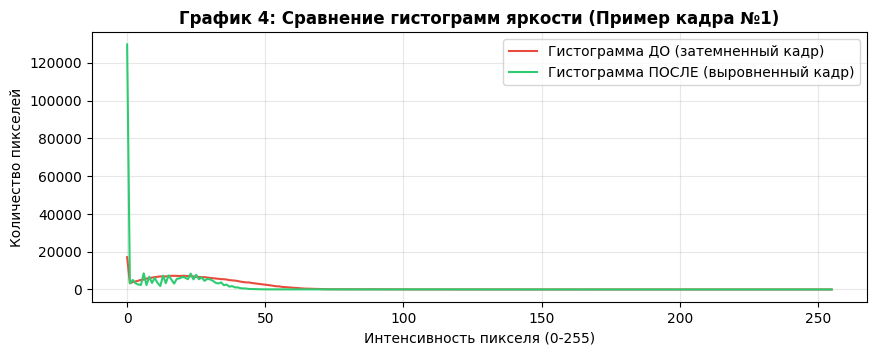

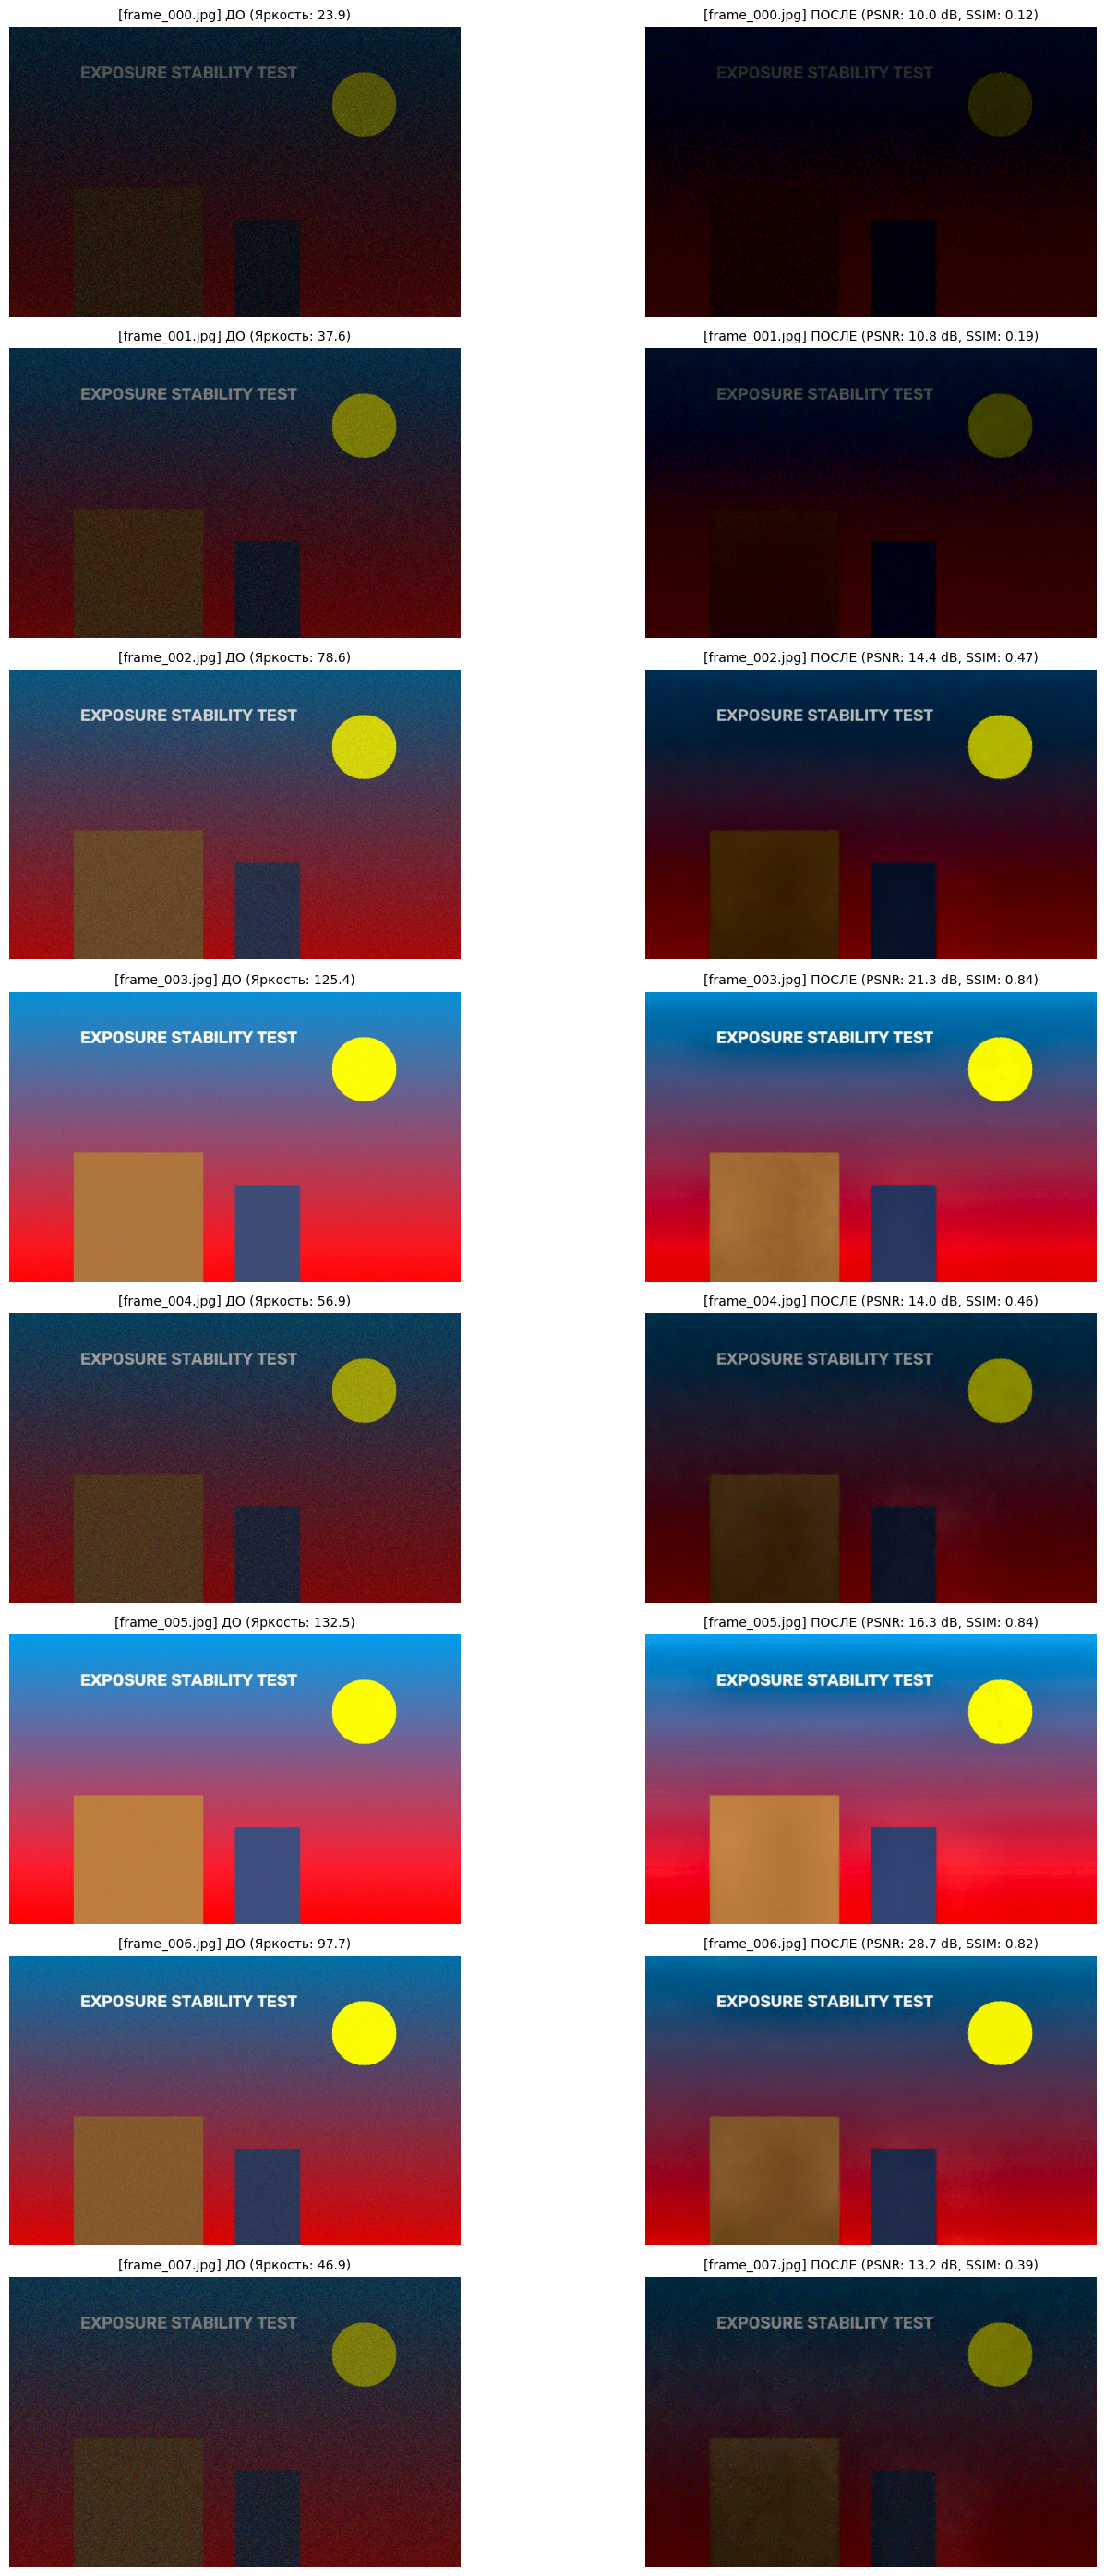

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Извлекаем данные из логов выполнения
f_names = [r["filename"] for r in execution_results]
orig_m = [r["orig_mean"] for r in execution_results]
proc_m = [r["proc_mean"] for r in execution_results]
psnr_vals = [r["psnr"] for r in execution_results]
ssim_vals = [r["ssim"] for r in execution_results]

# ГРАФИК 1: Анализ временной стабильности яркости (Устранение мерцания / Flicker)

plt.figure(figsize=(12, 4))
plt.plot(f_names, orig_m, marker='o', color='#e74c3c', linewidth=2, linestyle='--', label='Средняя яркость ДО (скачки / мерцание)')
plt.plot(f_names, proc_m, marker='s', color='#2ecc71', linewidth=2, linestyle='-', label='Средняя яркость ПОСЛЕ (стабилизирована)')
plt.axhline(y=125, color='#3498db', linestyle=':', label='Целевой уровень (Target = 125)')
plt.title("График 1: Стабилизация экспозиции серии кадров (Подавление фликеринга)", fontsize=12, fontweight='bold')
plt.xlabel("Кадры серии", fontsize=10)
plt.ylabel("Уровень яркости (0-255)", fontsize=10)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()


# ГРАФИК 2: Анализ межкадровой нестабильности (Производная яркости по времени)
# Считаем разницу яркости между соседними кадрами (абсолютный скачок)
flicker_orig = np.abs(np.diff(orig_m))
flicker_proc = np.abs(np.diff(proc_m))
diff_x_labels = f_names[1:]

plt.figure(figsize=(12, 3.5))
plt.bar(np.arange(len(flicker_orig)) - 0.2, flicker_orig, width=0.4, color='#e74c3c', alpha=0.8, label='Межкадровый скачок ДО')
plt.bar(np.arange(len(flicker_proc)) + 0.2, flicker_proc, width=0.4, color='#2ecc71', alpha=0.8, label='Межкадровый скачок ПОСЛЕ')
plt.xticks(ticks=np.arange(len(diff_x_labels)), labels=diff_x_labels)
plt.title("График 2: Количественная оценка межкадрового мерцания (Flicker Amplitude)", fontsize=12, fontweight='bold')
plt.xlabel("Переходы между кадрами", fontsize=10)
plt.ylabel("Абсолютная разница яркости", fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3, axis='y')
plt.show()


# ГРАФИК 3: Распределение метрик качества PSNR и SSIM по кадрам

fig, ax1 = plt.subplots(figsize=(12, 4))

color = '#8e44ad'
ax1.set_xlabel('Кадры серии', fontsize=10)
ax1.set_ylabel('PSNR (dB)', color=color, fontsize=10, fontweight='bold')
line1 = ax1.plot(f_names, psnr_vals, color=color, marker='^', linewidth=2, label='PSNR (dB)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, alpha=0.2)

ax2 = ax1.twinx()
color = '#d35400'
ax2.set_ylabel('SSIM ( Structural Similarity )', color=color, fontsize=10, fontweight='bold')
line2 = ax2.plot(f_names, ssim_vals, color=color, marker='d', linewidth=2, linestyle='-.', label='SSIM')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, 1.05)

plt.title("График 3: Динамика метрик качества (PSNR и SSIM) по кадрам серии", fontsize=12, fontweight='bold')
plt.show()


# ГРАФИК 4: Сравнение гистограмм распределения яркости (Для первого кадра)

sample_orig, sample_proc, _ = pipeline.process_frame(input_files[0])
hist_orig = cv2.calcHist([sample_orig], [0], None, [256], [0, 256])
hist_proc = cv2.calcHist([sample_proc], [0], None, [256], [0, 256])

plt.figure(figsize=(10, 3.5))
plt.plot(hist_orig, color='#e74c3c', linewidth=1.5, label='Гистограмма ДО (затемненный кадр)')
plt.plot(hist_proc, color='#2ecc71', linewidth=1.5, label='Гистограмма ПОСЛЕ (выровненный кадр)')
plt.title("График 4: Сравнение гистограмм яркости (Пример кадра №1)", fontsize=12, fontweight='bold')
plt.xlabel("Интенсивность пикселя (0-255)", fontsize=10)
plt.ylabel("Количество пикселей", fontsize=10)
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ВИЗУАЛИЗАЦИЯ ИЗОБРАЖЕНИЙ: Сравнение «До / После»

plt.figure(figsize=(16, 3.5 * len(visual_cache)))
for idx, (fname, orig_img, proc_img) in enumerate(visual_cache):
    orig_rgb = cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB)
    proc_rgb = cv2.cvtColor(proc_img, cv2.COLOR_BGR2RGB)

    plt.subplot(len(visual_cache), 2, 2 * idx + 1)
    plt.imshow(orig_rgb)
    plt.title(f"[{fname}] ДО (Яркость: {execution_results[idx]['orig_mean']:.1f})", fontsize=10)
    plt.axis('off')

    plt.subplot(len(visual_cache), 2, 2 * idx + 2)
    plt.imshow(proc_rgb)
    plt.title(f"[{fname}] ПОСЛЕ (PSNR: {execution_results[idx]['psnr']:.1f} dB, SSIM: {execution_results[idx]['ssim']:.2f})", fontsize=10)
    plt.axis('off')

plt.tight_layout()
plt.show()

# Блок 6: Научные выводы по проекту (Для отчета и защиты)

In [ ]:
# Расчет итоговой сводки по метрикам
avg_psnr = np.mean([r["psnr"] for r in execution_results])
avg_ssim = np.mean([r["ssim"] for r in execution_results])
max_psnr = np.max([r["psnr"] for r in execution_results])
min_psnr = np.min([r["psnr"] for r in execution_results])

print("=" * 70)
print("ИТОГОВАЯ АНАЛИТИЧЕСКАЯ СВОДКА ПРОЕКТА:")
print(f"• Среднее значение PSNR по всей серии: {avg_psnr:.2f} dB (Диапазон: [{min_psnr:.2f}, {max_psnr:.2f}])")
print(f"• Среднее значение SSIM по всей серии: {avg_ssim:.4f}")
print("=" * 70)

ИТОГОВАЯ АНАЛИТИЧЕСКАЯ СВОДКА ПРОЕКТА:
• Среднее значение PSNR по всей серии: 16.09 dB (Диапазон: [10.00, 28.67])
• Среднее значение SSIM по всей серии: 0.5161
